In [1]:
print("GeoSense Water Analysis")
print("L-band + S-band NISAR GCOV")
print("Environment is working!")

GeoSense Water Analysis
L-band + S-band NISAR GCOV
Environment is working!


In [6]:
from pathlib import Path
import sys

# Jupyter is already running from the main GeoSense repository
PROJECT_ROOT = Path.cwd()

# Make sure Python can use the existing GeoSense utilities
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:")
print(PROJECT_ROOT)

print("\nChecking important folders...")

print("nisar_utils:", (PROJECT_ROOT / "nisar_utils").exists())
print("config:", (PROJECT_ROOT / "config").exists())
print("notebooks:", (PROJECT_ROOT / "notebooks").exists())
print("outputs:", (PROJECT_ROOT / "outputs").exists())

print("\nGeoSense environment is ready.")

Project root:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training

Checking important folders...
nisar_utils: True
config: True
notebooks: True
outputs: True

GeoSense environment is ready.


In [7]:
from nisar_utils.config import load_config

cfg = load_config()

print("Configured NISAR file:")
print(cfg["nisar_file"])

print("\nConfiguration keys:")
print(list(cfg.keys()))

Configured NISAR file:
C:\Users\D. Sri Shashank\Desktop\Geosense\NISAR_Data\NISAR_S2_UR_GCOV_034_098_A_014_3700_DHNA_A_20261030T233811_20261030T233847_P00500_M_F_I_001.h5

Configuration keys:
['default_frequency', 'output_dir', 'max_plot_pixels', 'nisar_file', 'aoi', 'default_aoi', 'validated_projected_aoi', 'spatial_subset', 'spatial_subset_mode', 'polarimetric_mode', 'polarimetric_family', 'polarimetric_frequency', 'polarimetric_base']


In [8]:
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Output folder:")
print(OUTPUT_DIR)

print("\nFiles currently in outputs:")

for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(file.relative_to(OUTPUT_DIR))

Output folder:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs

Files currently in outputs:
module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.png
module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif
module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH_HVHV_Ratio_dB.png
module_08_visualization\NISAR_LSAR_098_014_A_20260912\HVHV.png
module_08_visualization\NISAR_LSAR_098_014_A_20260912\HVHV.tif
module_08_visualization\NISAR_LSAR_098_014_A_20260912\RGB_HHHH_HVHV_Ratio.png
module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.png
module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif
module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH_HVHV_Ratio_dB.png
module_08_visualization\NISAR_SSAR_098_014_A_20261030\HVHV.png
module_08_visualization\NISAR_SSAR_098_014_A_20261030\HVHV.tif
module_08_visualization\NISAR_SSAR_098_014_A_20261030\RGB_HHHH_HVHV_Ratio.png


In [9]:
from pathlib import Path

# Find the outputs folder
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Output folder:")
print(OUTPUT_DIR)

print("\nAll GeoTIFF files found:")

tif_files = sorted(OUTPUT_DIR.rglob("*.tif"))

for i, file in enumerate(tif_files, 1):
    print(f"{i}. {file.relative_to(OUTPUT_DIR)}")

print(f"\nTotal GeoTIFF files: {len(tif_files)}")

Output folder:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs

All GeoTIFF files found:
1. module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif
2. module_08_visualization\NISAR_LSAR_098_014_A_20260912\HVHV.tif
3. module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif
4. module_08_visualization\NISAR_SSAR_098_014_A_20261030\HVHV.tif

Total GeoTIFF files: 4


In [10]:
import rasterio
import numpy as np

print("========== L-BAND ==========")

L_FILE = tif_files[0]

with rasterio.open(L_FILE) as src:
    L = src.read(1)
    
    print("File:", L_FILE.name)
    print("Width:", src.width)
    print("Height:", src.height)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("NoData:", src.nodata)
    print("Data type:", src.dtypes[0])
    print("Minimum:", np.nanmin(L))
    print("Maximum:", np.nanmax(L))
    print("Mean:", np.nanmean(L))


print("\n========== S-BAND ==========")

S_FILE = tif_files[2]

with rasterio.open(S_FILE) as src:
    S = src.read(1)
    
    print("File:", S_FILE.name)
    print("Width:", src.width)
    print("Height:", src.height)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("NoData:", src.nodata)
    print("Data type:", src.dtypes[0])
    print("Minimum:", np.nanmin(S))
    print("Maximum:", np.nanmax(S))
    print("Mean:", np.nanmean(S))

========== L-BAND ==========
File: HHHH.tif
Width: 2126
Height: 2006
CRS: EPSG:32645
Resolution: (10.0, 10.0)
NoData: nan
Data type: float32
Minimum: 0.00095704943
Maximum: 5369.4375
Mean: 0.16890945

========== S-BAND ==========
File: HHHH.tif
Width: 2126
Height: 2006
CRS: EPSG:32645
Resolution: (10.0, 10.0)
NoData: nan
Data type: float32
Minimum: 0.00085372716
Maximum: 852.7362
Mean: 0.1764212


In [11]:
import rasterio
import numpy as np

# Your actual HHHH files
L_FILE = OUTPUT_DIR / "module_08_visualization" / "NISAR_LSAR_098_014_A_20260912" / "HHHH.tif"
S_FILE = OUTPUT_DIR / "module_08_visualization" / "NISAR_SSAR_098_014_A_20261030" / "HHHH.tif"


def inspect_raster(name, filepath):
    print("\n==============================")
    print(name)
    print("==============================")

    with rasterio.open(filepath) as src:
        data = src.read(1)

        print("File:", filepath)
        print("Width:", src.width)
        print("Height:", src.height)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("NoData:", src.nodata)
        print("Data type:", src.dtypes[0])

        valid = data[np.isfinite(data)]

        if src.nodata is not None:
            valid = valid[valid != src.nodata]

        print("Minimum:", valid.min())
        print("Maximum:", valid.max())
        print("Mean:", valid.mean())
        print("Median:", np.median(valid))


inspect_raster("L-BAND HHHH", L_FILE)
inspect_raster("S-BAND HHHH", S_FILE)


L-BAND HHHH
File: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif
Width: 2126
Height: 2006
CRS: EPSG:32645
Resolution: (10.0, 10.0)
NoData: nan
Data type: float32
Minimum: 0.00095704943
Maximum: 5369.4375
Mean: 0.16890945
Median: 0.06221819

S-BAND HHHH
File: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif
Width: 2126
Height: 2006
CRS: EPSG:32645
Resolution: (10.0, 10.0)
NoData: nan
Data type: float32
Minimum: 0.00085372716
Maximum: 852.7362
Mean: 0.1764212
Median: 0.11692734


L-band:
  Shape: (2006, 2126)
  dB range: -30.190657 to 37.299286

S-band:
  Shape: (2006, 2126)
  dB range: -30.68681 to 29.308147


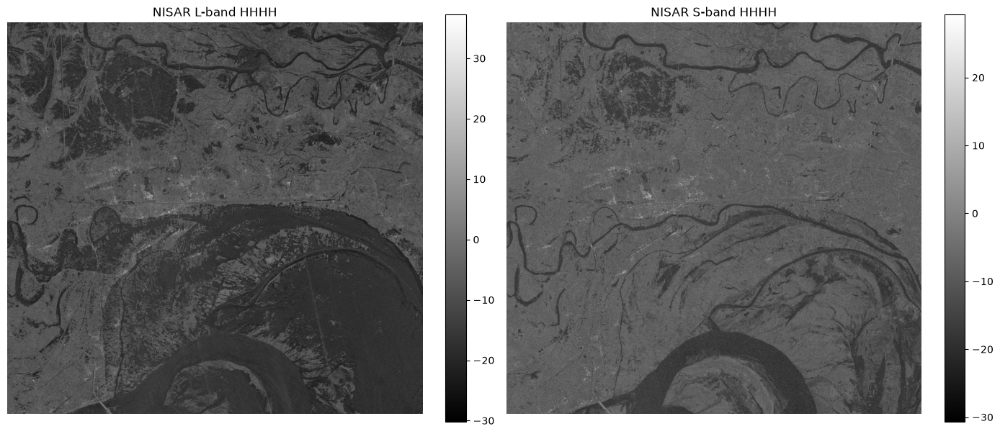

In [12]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# GeoTIFF files from Module 08
L_FILE = PROJECT_ROOT / "outputs" / "module_08_visualization" / \
         "NISAR_LSAR_098_014_A_20260912" / "HHHH.tif"

S_FILE = PROJECT_ROOT / "outputs" / "module_08_visualization" / \
         "NISAR_SSAR_098_014_A_20261030" / "HHHH.tif"


# Read L-band
with rasterio.open(L_FILE) as src:
    L = src.read(1)
    L_nodata = src.nodata

# Read S-band
with rasterio.open(S_FILE) as src:
    S = src.read(1)
    S_nodata = src.nodata


# Remove invalid values
L = np.where(np.isfinite(L), L, np.nan)
S = np.where(np.isfinite(S), S, np.nan)

# Convert to dB for easier visual interpretation
L_db = 10 * np.log10(L)
S_db = 10 * np.log10(S)

print("L-band:")
print("  Shape:", L.shape)
print("  dB range:", np.nanmin(L_db), "to", np.nanmax(L_db))

print("\nS-band:")
print("  Shape:", S.shape)
print("  dB range:", np.nanmin(S_db), "to", np.nanmax(S_db))


# Display both
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(L_db, cmap="gray")
axes[0].set_title("NISAR L-band HHHH")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], fraction=0.046)

im2 = axes[1].imshow(S_db, cmap="gray")
axes[1].set_title("NISAR S-band HHHH")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

Valid pixels: 4264756

L-band statistics:
Mean: -11.954447
Median: -12.060825

S-band statistics:
Mean: -9.83057
Median: -9.320839

L/S correlation: 0.4330226488782527


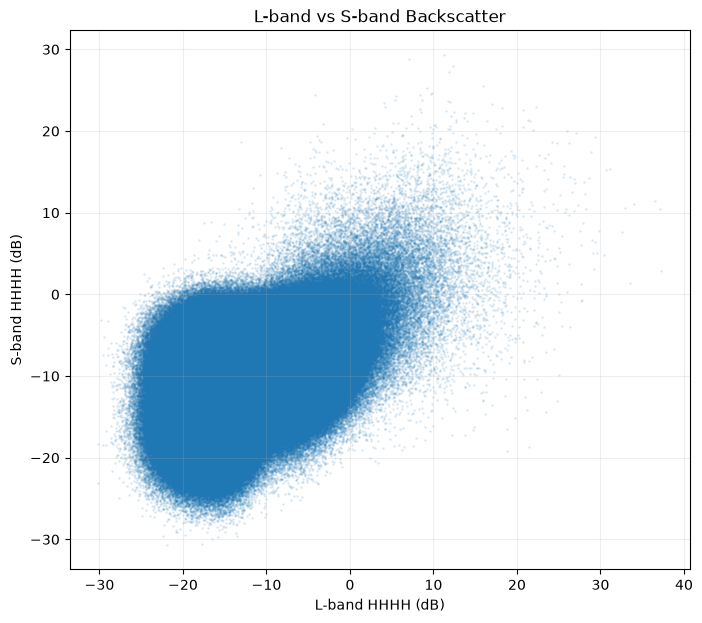

In [13]:
# ==========================================
# L-band vs S-band backscatter comparison
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Flatten both images
L_flat = L_db.flatten()
S_flat = S_db.flatten()

# Keep only pixels where BOTH bands are valid
valid = np.isfinite(L_flat) & np.isfinite(S_flat)

L_valid = L_flat[valid]
S_valid = S_flat[valid]

print("Valid pixels:", len(L_valid))

print("\nL-band statistics:")
print("Mean:", np.mean(L_valid))
print("Median:", np.median(L_valid))

print("\nS-band statistics:")
print("Mean:", np.mean(S_valid))
print("Median:", np.median(S_valid))

# Correlation between the two bands
correlation = np.corrcoef(L_valid, S_valid)[0, 1]

print("\nL/S correlation:", correlation)


# Scatter plot
plt.figure(figsize=(8, 7))

plt.scatter(
    L_valid,
    S_valid,
    s=1,
    alpha=0.1
)

plt.xlabel("L-band HHHH (dB)")
plt.ylabel("S-band HHHH (dB)")
plt.title("L-band vs S-band Backscatter")

plt.grid(True, alpha=0.2)
plt.show()

L-band threshold: -15 dB
S-band threshold: -15 dB

Water candidate pixels: 429187
Total pixels: 4264756
Candidate water area: 10.063576908034129 %


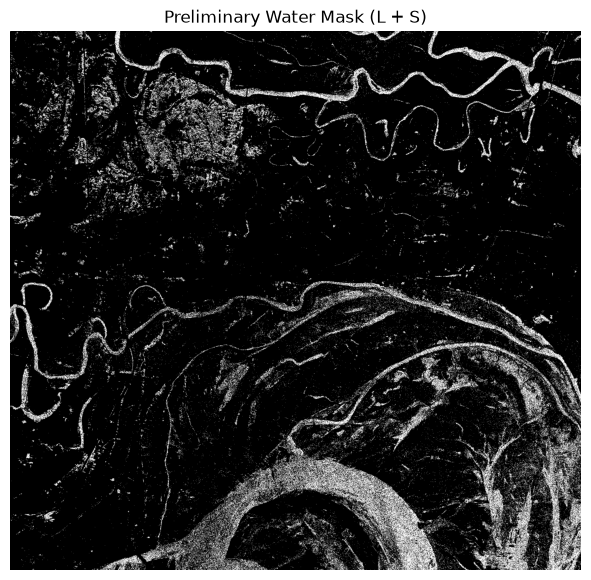

In [14]:
# ==========================================
# Preliminary L + S band water detection
# ==========================================

# Thresholds for low radar backscatter
L_THRESHOLD = -15
S_THRESHOLD = -15

# Water candidate = dark in BOTH bands
water_mask = (
    (L_db < L_THRESHOLD) &
    (S_db < S_THRESHOLD)
)

# Count pixels
water_pixels = np.sum(water_mask)
total_pixels = water_mask.size
water_percentage = (water_pixels / total_pixels) * 100

print("L-band threshold:", L_THRESHOLD, "dB")
print("S-band threshold:", S_THRESHOLD, "dB")

print("\nWater candidate pixels:", water_pixels)
print("Total pixels:", total_pixels)
print("Candidate water area:", water_percentage, "%")


# Display mask
plt.figure(figsize=(10, 7))

plt.imshow(water_mask, cmap="gray")
plt.title("Preliminary Water Mask (L + S)")
plt.axis("off")

plt.show()

L-band percentiles:
 1% : -22.18 dB
 5% : -20.01 dB
10% : -18.78 dB
15% : -17.91 dB
20% : -17.16 dB
25% : -16.47 dB
30% : -15.77 dB
40% : -14.16 dB
50% : -12.06 dB

S-band percentiles:
 1% : -20.97 dB
 5% : -18.00 dB
10% : -16.13 dB
15% : -14.71 dB
20% : -13.55 dB
25% : -12.58 dB
30% : -11.76 dB
40% : -10.43 dB
50% : -9.32 dB


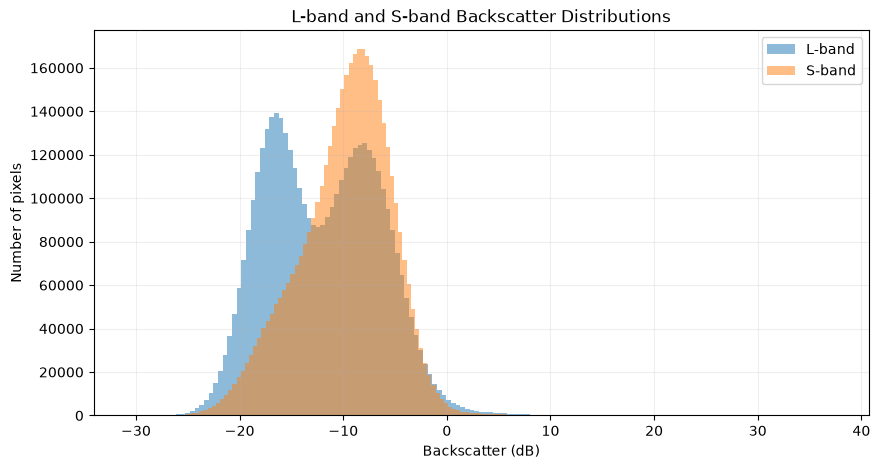

In [15]:
# ==========================================
# Find useful L/S backscatter thresholds
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Percentiles of each band
percentiles = [1, 5, 10, 15, 20, 25, 30, 40, 50]

print("L-band percentiles:")
for p in percentiles:
    print(f"{p:>2}% : {np.percentile(L_valid, p):.2f} dB")

print("\nS-band percentiles:")
for p in percentiles:
    print(f"{p:>2}% : {np.percentile(S_valid, p):.2f} dB")


# Histograms
plt.figure(figsize=(10, 5))

plt.hist(L_valid, bins=150, alpha=0.5, label="L-band")
plt.hist(S_valid, bins=150, alpha=0.5, label="S-band")

plt.xlabel("Backscatter (dB)")
plt.ylabel("Number of pixels")
plt.title("L-band and S-band Backscatter Distributions")
plt.legend()
plt.grid(True, alpha=0.2)

plt.show()

L-band HHHH files found: 1
S-band HHHH files found: 1

Using:
L-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif
S-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif

Image shapes:
L-band: (2006, 2126)
S-band: (2006, 2126)

Valid pixels: 4264756
Total pixels: 4264756

========== L-BAND ==========
Minimum : 0.00095704943 dB
Maximum : 5369.4375 dB
Mean    : 0.16890945 dB
Median  : 0.06221819 dB

========== S-BAND ==========
Minimum : 0.00085372716 dB
Maximum : 852.7362 dB
Mean    : 0.1764212 dB
Median  : 0.11692734 dB

========== WATER DETECTION ==========
L-band threshold: -15 dB
S-band threshold: -15 dB

Water candidate pixels: 0
Valid pixels: 4264756
Estimated water candidate area: 0.0 %


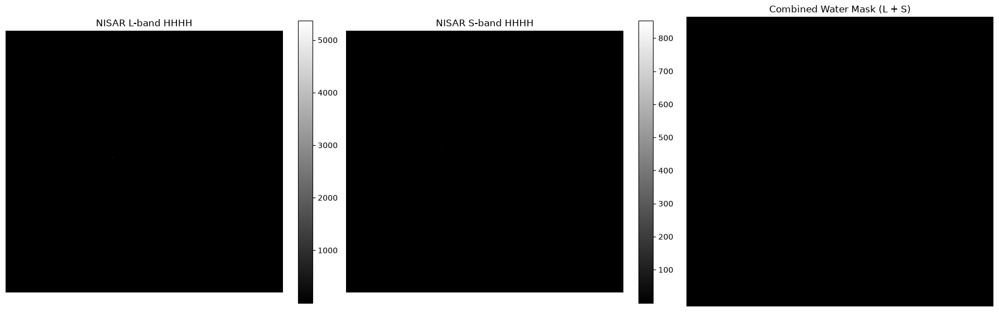

In [17]:
# ==========================================================
# L-BAND + S-BAND WATER DETECTION
# ==========================================================

from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. Find L-band and S-band HHHH GeoTIFFs
# ----------------------------------------------------------

OUTPUT_DIR = PROJECT_ROOT / "outputs"

L_FILES = sorted(
    OUTPUT_DIR.rglob("*LSAR*/*HHHH.tif")
)

S_FILES = sorted(
    OUTPUT_DIR.rglob("*SSAR*/*HHHH.tif")
)

print("L-band HHHH files found:", len(L_FILES))
print("S-band HHHH files found:", len(S_FILES))

if not L_FILES or not S_FILES:
    raise FileNotFoundError(
        "Could not find both L-band and S-band HHHH GeoTIFF files."
    )

# Use the most recent file from each band
L_FILE = L_FILES[-1]
S_FILE = S_FILES[-1]

print("\nUsing:")
print("L-band:", L_FILE)
print("S-band:", S_FILE)


# ----------------------------------------------------------
# 2. Load BOTH bands
# ----------------------------------------------------------

with rasterio.open(L_FILE) as src:
    L = src.read(1).astype(np.float32)
    L_nodata = src.nodata

with rasterio.open(S_FILE) as src:
    S = src.read(1).astype(np.float32)
    S_nodata = src.nodata


# ----------------------------------------------------------
# 3. Check that the images have the same dimensions
# ----------------------------------------------------------

print("\nImage shapes:")
print("L-band:", L.shape)
print("S-band:", S.shape)

if L.shape != S.shape:
    raise ValueError("L-band and S-band images have different dimensions.")


# ----------------------------------------------------------
# 4. Remove invalid / NoData pixels
# ----------------------------------------------------------

L_valid = np.isfinite(L)
S_valid = np.isfinite(S)

if L_nodata is not None:
    L_valid &= L != L_nodata

if S_nodata is not None:
    S_valid &= S != S_nodata

valid = L_valid & S_valid

print("\nValid pixels:", np.sum(valid))
print("Total pixels:", L.size)


# ----------------------------------------------------------
# 5. Calculate statistics for BOTH bands
# ----------------------------------------------------------

L_values = L[valid]
S_values = S[valid]

print("\n========== L-BAND ==========")
print("Minimum :", np.min(L_values), "dB")
print("Maximum :", np.max(L_values), "dB")
print("Mean    :", np.mean(L_values), "dB")
print("Median  :", np.median(L_values), "dB")

print("\n========== S-BAND ==========")
print("Minimum :", np.min(S_values), "dB")
print("Maximum :", np.max(S_values), "dB")
print("Mean    :", np.mean(S_values), "dB")
print("Median  :", np.median(S_values), "dB")


# ----------------------------------------------------------
# 6. Water thresholds
# ----------------------------------------------------------

L_THRESHOLD = -15
S_THRESHOLD = -15

print("\n========== WATER DETECTION ==========")
print("L-band threshold:", L_THRESHOLD, "dB")
print("S-band threshold:", S_THRESHOLD, "dB")


# ----------------------------------------------------------
# 7. Create combined L + S water mask
# ----------------------------------------------------------

water_mask = (
    valid &
    (L < L_THRESHOLD) &
    (S < S_THRESHOLD)
)

water_pixels = np.sum(water_mask)
valid_pixels = np.sum(valid)

water_percentage = (
    water_pixels / valid_pixels * 100
)

print("\nWater candidate pixels:", water_pixels)
print("Valid pixels:", valid_pixels)
print("Estimated water candidate area:",
      water_percentage, "%")


# ----------------------------------------------------------
# 8. Display BOTH bands + combined water mask
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# L-band
L_display = np.where(valid, L, np.nan)

im1 = axes[0].imshow(L_display, cmap="gray")
axes[0].set_title("NISAR L-band HHHH")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], fraction=0.046)

# S-band
S_display = np.where(valid, S, np.nan)

im2 = axes[1].imshow(S_display, cmap="gray")
axes[1].set_title("NISAR S-band HHHH")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], fraction=0.046)

# Combined water mask
axes[2].imshow(water_mask, cmap="gray")
axes[2].set_title("Combined Water Mask (L + S)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

========== WATER DETECTION ==========
L-band threshold: -15 dB
S-band threshold: -15 dB

Water candidate pixels: 429187
Valid pixels: 4264756
Estimated water candidate area: 10.063576908034129 %


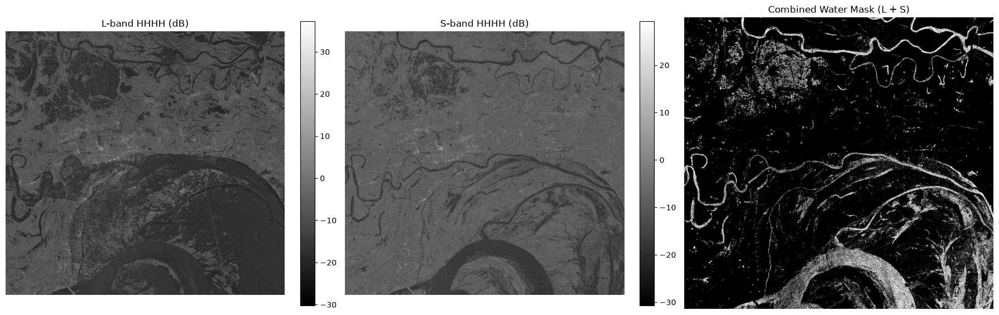

In [18]:
# ==========================================================
# L-BAND + S-BAND WATER DETECTION IN dB
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# Convert linear backscatter to dB
# Formula: dB = 10 * log10(linear value)
# ----------------------------------------------------------

L_dB = 10 * np.log10(np.maximum(L, 1e-10))
S_dB = 10 * np.log10(np.maximum(S, 1e-10))

# ----------------------------------------------------------
# Water thresholds
# ----------------------------------------------------------

L_THRESHOLD = -15
S_THRESHOLD = -15

# ----------------------------------------------------------
# Combined water mask
# A pixel must satisfy BOTH L-band and S-band conditions
# ----------------------------------------------------------

water_mask = (
    valid &
    (L_dB < L_THRESHOLD) &
    (S_dB < S_THRESHOLD)
)

# ----------------------------------------------------------
# Statistics
# ----------------------------------------------------------

water_pixels = np.sum(water_mask)
valid_pixels = np.sum(valid)

water_percentage = (
    water_pixels / valid_pixels * 100
)

print("========== WATER DETECTION ==========")
print("L-band threshold:", L_THRESHOLD, "dB")
print("S-band threshold:", S_THRESHOLD, "dB")
print()
print("Water candidate pixels:", water_pixels)
print("Valid pixels:", valid_pixels)
print("Estimated water candidate area:",
      water_percentage, "%")


# ----------------------------------------------------------
# Display L-band, S-band and combined mask
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

L_display = np.where(valid, L_dB, np.nan)
S_display = np.where(valid, S_dB, np.nan)

im1 = axes[0].imshow(L_display, cmap="gray")
axes[0].set_title("L-band HHHH (dB)")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], fraction=0.046)

im2 = axes[1].imshow(S_display, cmap="gray")
axes[1].set_title("S-band HHHH (dB)")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], fraction=0.046)

axes[2].imshow(water_mask, cmap="gray")
axes[2].set_title("Combined Water Mask (L + S)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

WATER MASK REFINEMENT

Original candidate pixels: 429187
Original candidate area: 10.064 %

Cleaned water pixels: 97792
Cleaned water area: 2.293 %

Regions detected: 72643


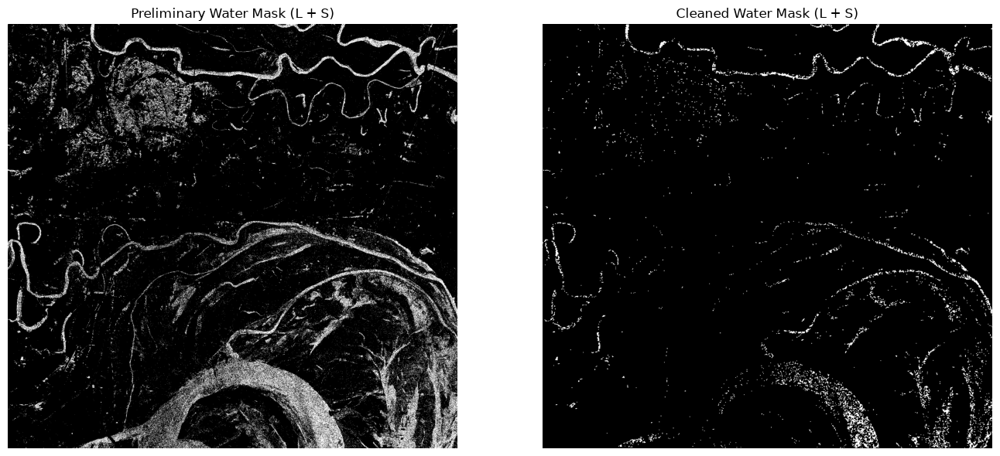

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# ============================================================
# CLEAN THE PRELIMINARY L + S WATER MASK
# ============================================================

print("=" * 55)
print("WATER MASK REFINEMENT")
print("=" * 55)

# Start from the original L + S mask
clean_mask = water_mask.copy()

# ------------------------------------------------------------
# 1. Find connected water regions
# ------------------------------------------------------------

labeled, num_features = ndimage.label(clean_mask)

# Size of every connected region
region_sizes = np.bincount(labeled.ravel())

# Minimum region size
MIN_REGION_SIZE = 20

# IMPORTANT:
# label 0 = background, so we MUST exclude it
clean_mask = (
    (labeled != 0) &
    (region_sizes[labeled] >= MIN_REGION_SIZE)
)

# ------------------------------------------------------------
# 2. Morphological cleaning
# ------------------------------------------------------------

# Remove tiny isolated pixels
clean_mask = ndimage.binary_opening(
    clean_mask,
    structure=np.ones((3, 3))
)

# Close small gaps
clean_mask = ndimage.binary_closing(
    clean_mask,
    structure=np.ones((3, 3))
)

# ------------------------------------------------------------
# 3. Calculate statistics
# ------------------------------------------------------------

original_pixels = np.sum(water_mask)
clean_water_pixels = np.sum(clean_mask)
total_pixels = clean_mask.size

original_percentage = (
    original_pixels / total_pixels * 100
)

clean_percentage = (
    clean_water_pixels / total_pixels * 100
)

print()
print("Original candidate pixels:", original_pixels)
print("Original candidate area:", round(original_percentage, 3), "%")

print()
print("Cleaned water pixels:", clean_water_pixels)
print("Cleaned water area:", round(clean_percentage, 3), "%")

print()
print("Regions detected:", num_features)

# ------------------------------------------------------------
# 4. Compare the masks
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(water_mask, cmap="gray")
axes[0].set_title("Preliminary Water Mask (L + S)")
axes[0].axis("off")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("Cleaned Water Mask (L + S)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

L-band HHHH files found: 1
S-band HHHH files found: 1

Using:
L-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif
S-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif

Image shapes:
L-band: (2006, 2126)
S-band: (2006, 2126)

Valid pixels: 4264756
Total pixels: 4264756

========== L-BAND ==========
Minimum : -30.190657 dB
Maximum : 37.299286 dB
Mean    : -11.954447 dB
Median  : -12.060825 dB

========== S-BAND ==========
Minimum : -30.68681 dB
Maximum : 29.308147 dB
Mean    : -9.83057 dB
Median  : -9.320839 dB

========== WATER DETECTION ==========
L-band threshold: -15 dB
S-band threshold: -15 dB

Water candidate pixels: 429187
Valid pixels: 4264756
Estimated water candidate area: 10.063576908034129 %


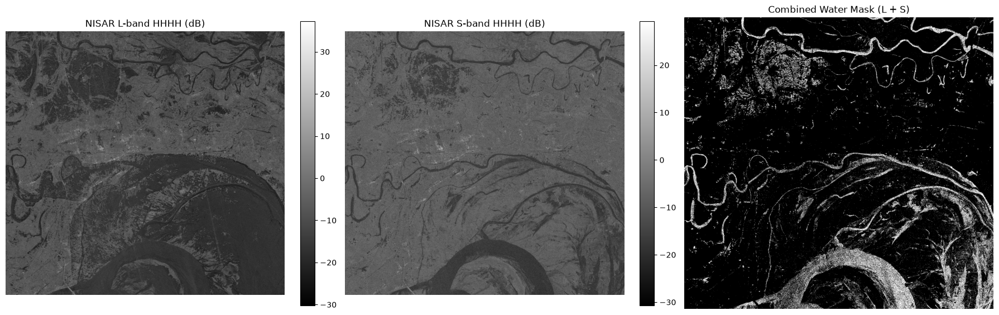

In [29]:
# ==========================================================
# L-BAND + S-BAND WATER DETECTION
# ==========================================================

from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. Find L-band and S-band HHHH GeoTIFFs
# ----------------------------------------------------------

OUTPUT_DIR = PROJECT_ROOT / "outputs"

L_FILES = sorted(
    OUTPUT_DIR.rglob("*LSAR*/*HHHH.tif")
)

S_FILES = sorted(
    OUTPUT_DIR.rglob("*SSAR*/*HHHH.tif")
)

print("L-band HHHH files found:", len(L_FILES))
print("S-band HHHH files found:", len(S_FILES))

if not L_FILES or not S_FILES:
    raise FileNotFoundError(
        "Could not find both L-band and S-band HHHH GeoTIFF files."
    )

L_FILE = L_FILES[-1]
S_FILE = S_FILES[-1]

print("\nUsing:")
print("L-band:", L_FILE)
print("S-band:", S_FILE)


# ----------------------------------------------------------
# 2. Load BOTH bands
# ----------------------------------------------------------

with rasterio.open(L_FILE) as src:
    L_raw = src.read(1).astype(np.float32)
    L_nodata = src.nodata

with rasterio.open(S_FILE) as src:
    S_raw = src.read(1).astype(np.float32)
    S_nodata = src.nodata


# ----------------------------------------------------------
# 3. Check dimensions
# ----------------------------------------------------------

print("\nImage shapes:")
print("L-band:", L_raw.shape)
print("S-band:", S_raw.shape)

if L_raw.shape != S_raw.shape:
    raise ValueError(
        "L-band and S-band images have different dimensions."
    )


# ----------------------------------------------------------
# 4. Create valid-pixel masks BEFORE dB conversion
# ----------------------------------------------------------

L_valid = np.isfinite(L_raw) & (L_raw > 0)
S_valid = np.isfinite(S_raw) & (S_raw > 0)

if L_nodata is not None:
    L_valid &= L_raw != L_nodata

if S_nodata is not None:
    S_valid &= S_raw != S_nodata

valid = L_valid & S_valid

print("\nValid pixels:", np.sum(valid))
print("Total pixels:", L_raw.size)


# ----------------------------------------------------------
# 5. Convert linear backscatter -> dB
# ----------------------------------------------------------

L = np.full(L_raw.shape, np.nan, dtype=np.float32)
S = np.full(S_raw.shape, np.nan, dtype=np.float32)

L[L_valid] = 10 * np.log10(L_raw[L_valid])
S[S_valid] = 10 * np.log10(S_raw[S_valid])


# ----------------------------------------------------------
# 6. Calculate statistics in dB
# ----------------------------------------------------------

L_values = L[valid]
S_values = S[valid]

print("\n========== L-BAND ==========")
print("Minimum :", np.min(L_values), "dB")
print("Maximum :", np.max(L_values), "dB")
print("Mean    :", np.mean(L_values), "dB")
print("Median  :", np.median(L_values), "dB")

print("\n========== S-BAND ==========")
print("Minimum :", np.min(S_values), "dB")
print("Maximum :", np.max(S_values), "dB")
print("Mean    :", np.mean(S_values), "dB")
print("Median  :", np.median(S_values), "dB")


# ----------------------------------------------------------
# 7. Water thresholds
# ----------------------------------------------------------

L_THRESHOLD = -15
S_THRESHOLD = -15

print("\n========== WATER DETECTION ==========")
print("L-band threshold:", L_THRESHOLD, "dB")
print("S-band threshold:", S_THRESHOLD, "dB")


# ----------------------------------------------------------
# 8. Create combined L + S water mask
# ----------------------------------------------------------

water_mask = (
    valid &
    (L < L_THRESHOLD) &
    (S < S_THRESHOLD)
)

water_pixels = np.sum(water_mask)
valid_pixels = np.sum(valid)

water_percentage = (
    water_pixels / valid_pixels * 100
)

print("\nWater candidate pixels:", water_pixels)
print("Valid pixels:", valid_pixels)
print(
    "Estimated water candidate area:",
    water_percentage,
    "%"
)


# ----------------------------------------------------------
# 9. Display BOTH bands + combined water mask
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# L-band
im1 = axes[0].imshow(L, cmap="gray")
axes[0].set_title("NISAR L-band HHHH (dB)")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], fraction=0.046)

# S-band
im2 = axes[1].imshow(S, cmap="gray")
axes[1].set_title("NISAR S-band HHHH (dB)")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], fraction=0.046)

# Combined water mask
axes[2].imshow(water_mask, cmap="gray")
axes[2].set_title("Combined Water Mask (L + S)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

          WATER MASK REFINEMENT

Initial water candidate pixels: 429187
Initial water candidate area: 10.063576908034129 %

Minimum region size: 50 pixels
Regions detected: 72643
Cleaned water pixels: 225339
Cleaned water area: 5.283748941322786 %


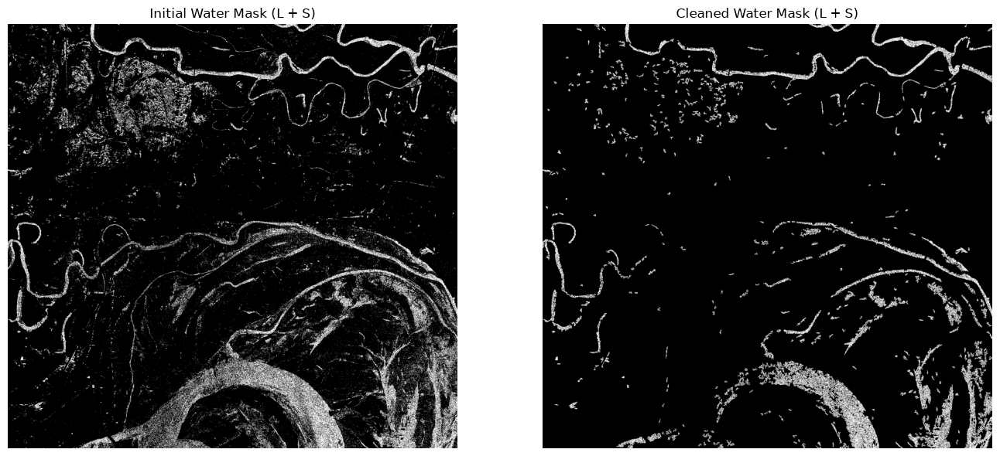


Refined water mask is ready.


In [30]:
# ==========================================================
# WATER MASK REFINEMENT
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

print("================================================")
print("          WATER MASK REFINEMENT")
print("================================================")

# ----------------------------------------------------------
# 1. Start with the existing L+S water mask
# ----------------------------------------------------------

initial_mask = water_mask.copy()

print("\nInitial water candidate pixels:",
      np.sum(initial_mask))

print("Initial water candidate area:",
      np.sum(initial_mask) / np.sum(valid) * 100,
      "%")


# ----------------------------------------------------------
# 2. Remove very small isolated regions
# ----------------------------------------------------------

# Label connected regions
labeled_mask, num_regions = ndimage.label(initial_mask)

# Calculate size of every region
region_sizes = np.bincount(labeled_mask.ravel())

# Minimum region size
MIN_REGION_SIZE = 50

# Keep only regions larger than the minimum size
clean_mask = np.zeros_like(initial_mask, dtype=bool)

for region_id in range(1, num_regions + 1):

    if region_sizes[region_id] >= MIN_REGION_SIZE:
        clean_mask[labeled_mask == region_id] = True


# ----------------------------------------------------------
# 3. Statistics after cleaning
# ----------------------------------------------------------

clean_pixels = np.sum(clean_mask)
clean_percentage = (
    clean_pixels / np.sum(valid) * 100
)

print("\nMinimum region size:",
      MIN_REGION_SIZE, "pixels")

print("Regions detected:",
      num_regions)

print("Cleaned water pixels:",
      clean_pixels)

print("Cleaned water area:",
      clean_percentage, "%")


# ----------------------------------------------------------
# 4. Compare original and cleaned masks
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(initial_mask, cmap="gray")
axes[0].set_title("Initial Water Mask (L + S)")
axes[0].axis("off")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("Cleaned Water Mask (L + S)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 5. Save the cleaned mask for later processing
# ----------------------------------------------------------

refined_water_mask = clean_mask

print("\nRefined water mask is ready.")

       WATER MASK VALIDATION

Refined water pixels:
L-band: 225339
S-band: 225339

========== DETECTED WATER: L-BAND ==========
Minimum : -30.190657 dB
Maximum : -15.000247 dB
Mean    : -18.234974 dB
Median  : -17.960022 dB

========== DETECTED WATER: S-BAND ==========
Minimum : -30.68681 dB
Maximum : -15.000002 dB
Mean    : -18.138119 dB
Median  : -17.810295 dB

========== WATER L-BAND PERCENTILES ==========
 1% : -23.83 dB
 5% : -22.02 dB
10% : -21.07 dB
25% : -19.54 dB
50% : -17.96 dB
75% : -16.63 dB
90% : -15.75 dB
95% : -15.40 dB
99% : -15.09 dB

========== WATER S-BAND PERCENTILES ==========
 1% : -24.08 dB
 5% : -22.11 dB
10% : -21.10 dB
25% : -19.46 dB
50% : -17.81 dB
75% : -16.45 dB
90% : -15.62 dB
95% : -15.32 dB
99% : -15.06 dB

========== THRESHOLD CHECK ==========
L-band below -15 dB: 225339 / 225339 ( 100.0 %)
S-band below -15 dB: 225339 / 225339 ( 100.0 %)


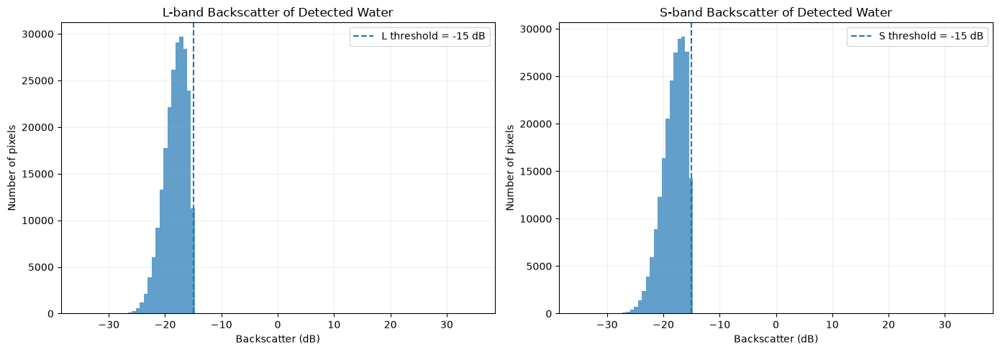

In [31]:
# ==========================================================
# L-BAND + S-BAND WATER MASK VALIDATION
# ==========================================================

print("================================================")
print("       WATER MASK VALIDATION")
print("================================================")

# ----------------------------------------------------------
# 1. Extract backscatter values inside the refined mask
# ----------------------------------------------------------

water_L = L[refined_water_mask]
water_S = S[refined_water_mask]

# Remove any unexpected non-finite values
water_L = water_L[np.isfinite(water_L)]
water_S = water_S[np.isfinite(water_S)]

print("\nRefined water pixels:")
print("L-band:", len(water_L))
print("S-band:", len(water_S))


# ----------------------------------------------------------
# 2. Calculate statistics for detected water
# ----------------------------------------------------------

print("\n========== DETECTED WATER: L-BAND ==========")

print("Minimum :", np.min(water_L), "dB")
print("Maximum :", np.max(water_L), "dB")
print("Mean    :", np.mean(water_L), "dB")
print("Median  :", np.median(water_L), "dB")

print("\n========== DETECTED WATER: S-BAND ==========")

print("Minimum :", np.min(water_S), "dB")
print("Maximum :", np.max(water_S), "dB")
print("Mean    :", np.mean(water_S), "dB")
print("Median  :", np.median(water_S), "dB")


# ----------------------------------------------------------
# 3. Percentiles
# ----------------------------------------------------------

percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]

print("\n========== WATER L-BAND PERCENTILES ==========")

for p in percentiles:
    print(f"{p:2d}% : {np.percentile(water_L, p):.2f} dB")

print("\n========== WATER S-BAND PERCENTILES ==========")

for p in percentiles:
    print(f"{p:2d}% : {np.percentile(water_S, p):.2f} dB")


# ----------------------------------------------------------
# 4. Check how many detected water pixels
#    actually satisfy the -15 dB thresholds
# ----------------------------------------------------------

L_below_threshold = water_L < L_THRESHOLD
S_below_threshold = water_S < S_THRESHOLD

print("\n========== THRESHOLD CHECK ==========")

print(
    "L-band below -15 dB:",
    np.sum(L_below_threshold),
    "/",
    len(water_L),
    "(",
    np.mean(L_below_threshold) * 100,
    "%)"
)

print(
    "S-band below -15 dB:",
    np.sum(S_below_threshold),
    "/",
    len(water_S),
    "(",
    np.mean(S_below_threshold) * 100,
    "%)"
)


# ----------------------------------------------------------
# 5. Visualize detected water pixels
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    water_L,
    bins=100,
    alpha=0.7,
    range=(-35, 35)
)

axes[0].axvline(
    L_THRESHOLD,
    linestyle="--",
    label="L threshold = -15 dB"
)

axes[0].set_title("L-band Backscatter of Detected Water")
axes[0].set_xlabel("Backscatter (dB)")
axes[0].set_ylabel("Number of pixels")
axes[0].legend()
axes[0].grid(alpha=0.2)


axes[1].hist(
    water_S,
    bins=100,
    alpha=0.7,
    range=(-35, 35)
)

axes[1].axvline(
    S_THRESHOLD,
    linestyle="--",
    label="S threshold = -15 dB"
)

axes[1].set_title("S-band Backscatter of Detected Water")
axes[1].set_xlabel("Backscatter (dB)")
axes[1].set_ylabel("Number of pixels")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

     L-BAND vs S-BAND WATER SIGNATURE

Sample size: 50000

L-band statistics:
Mean   : -18.238085 dB
Median : -17.964554 dB

S-band statistics:
Mean   : -18.147406 dB
Median : -17.82121 dB

L - S difference:
Mean   : -0.0906796 dB
Median : -0.12734795 dB
Minimum: -11.936734 dB
Maximum: 11.795105 dB


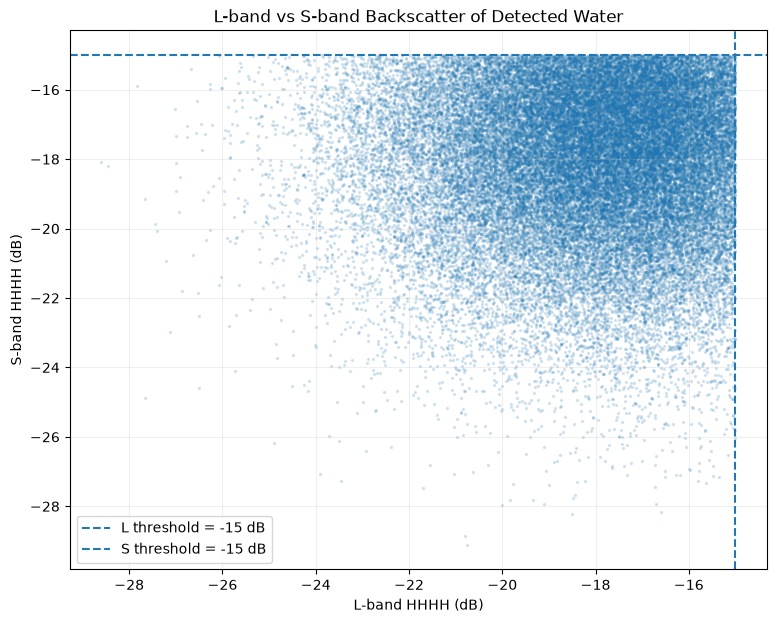

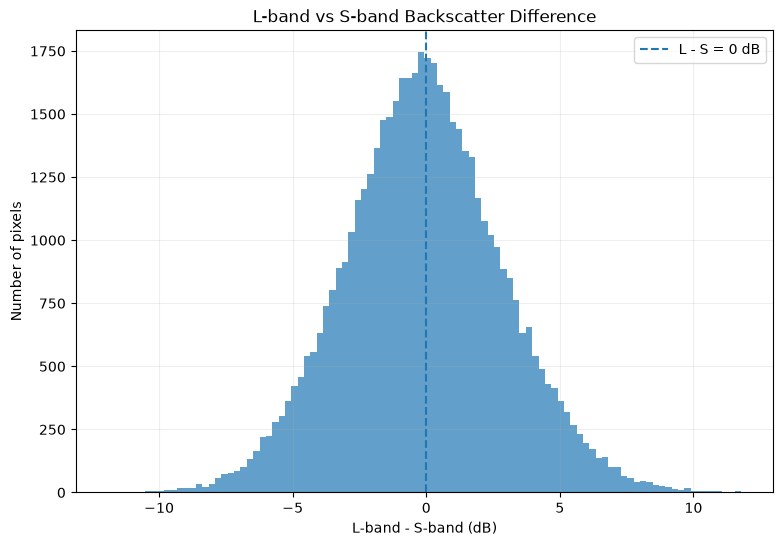

In [32]:
# ==========================================================
# L-BAND vs S-BAND WATER SIGNATURE ANALYSIS
# ==========================================================

print("================================================")
print("     L-BAND vs S-BAND WATER SIGNATURE")
print("================================================")

# ----------------------------------------------------------
# 1. Randomly sample detected water pixels
# ----------------------------------------------------------

sample_size = min(50000, len(water_L))

rng = np.random.default_rng(42)

sample_idx = rng.choice(
    len(water_L),
    sample_size,
    replace=False
)

L_sample = water_L[sample_idx]
S_sample = water_S[sample_idx]


# ----------------------------------------------------------
# 2. Calculate L/S difference
# ----------------------------------------------------------

LS_difference = L_sample - S_sample

print("\nSample size:", sample_size)

print("\nL-band statistics:")
print("Mean   :", np.mean(L_sample), "dB")
print("Median :", np.median(L_sample), "dB")

print("\nS-band statistics:")
print("Mean   :", np.mean(S_sample), "dB")
print("Median :", np.median(S_sample), "dB")

print("\nL - S difference:")
print("Mean   :", np.mean(LS_difference), "dB")
print("Median :", np.median(LS_difference), "dB")
print("Minimum:", np.min(LS_difference), "dB")
print("Maximum:", np.max(LS_difference), "dB")


# ----------------------------------------------------------
# 3. L-band vs S-band scatter plot
# ----------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.scatter(
    L_sample,
    S_sample,
    s=2,
    alpha=0.15
)

plt.axvline(
    L_THRESHOLD,
    linestyle="--",
    label="L threshold = -15 dB"
)

plt.axhline(
    S_THRESHOLD,
    linestyle="--",
    label="S threshold = -15 dB"
)

plt.xlabel("L-band HHHH (dB)")
plt.ylabel("S-band HHHH (dB)")
plt.title("L-band vs S-band Backscatter of Detected Water")
plt.legend()
plt.grid(alpha=0.2)

plt.show()


# ----------------------------------------------------------
# 4. Distribution of L-S difference
# ----------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.hist(
    LS_difference,
    bins=100,
    alpha=0.7
)

plt.axvline(
    0,
    linestyle="--",
    label="L - S = 0 dB"
)

plt.xlabel("L-band - S-band (dB)")
plt.ylabel("Number of pixels")
plt.title("L-band vs S-band Backscatter Difference")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

          WATER CONFIDENCE MAP

Refined water pixels: 225339
High-confidence water: 51855 ( 1.2158960559525562 % of valid pixels)
Moderate-confidence water: 173484 ( 4.06785288537023 % of valid pixels)


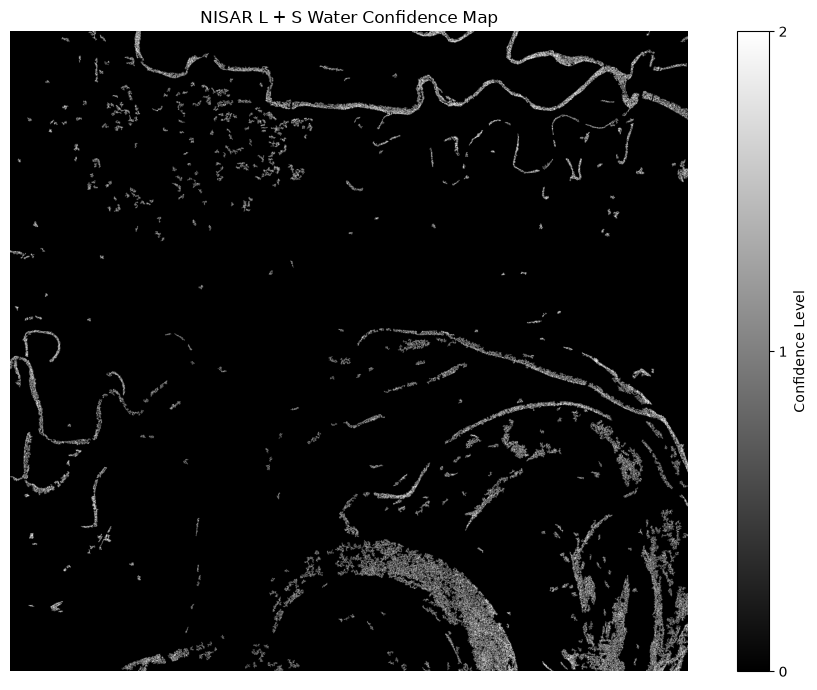


Final water mask ready.
Confidence map ready.


In [33]:
# ==========================================================
# WATER CONFIDENCE MAP
# ==========================================================

print("================================================")
print("          WATER CONFIDENCE MAP")
print("================================================")

# ----------------------------------------------------------
# 1. Calculate how far each pixel is below the threshold
# ----------------------------------------------------------

# Positive value = pixel is below threshold
L_margin = L_THRESHOLD - L
S_margin = S_THRESHOLD - S


# ----------------------------------------------------------
# 2. Define confidence levels
# ----------------------------------------------------------

# High confidence:
# At least 3 dB below threshold in BOTH bands
high_confidence = (
    refined_water_mask &
    (L_margin >= 3) &
    (S_margin >= 3)
)

# Moderate confidence:
# Detected by the refined mask but not high confidence
moderate_confidence = (
    refined_water_mask &
    ~high_confidence
)


# ----------------------------------------------------------
# 3. Count pixels
# ----------------------------------------------------------

high_pixels = np.sum(high_confidence)
moderate_pixels = np.sum(moderate_confidence)
total_water = np.sum(refined_water_mask)

print("\nRefined water pixels:", total_water)

print(
    "High-confidence water:",
    high_pixels,
    "(",
    high_pixels / np.sum(valid) * 100,
    "% of valid pixels)"
)

print(
    "Moderate-confidence water:",
    moderate_pixels,
    "(",
    moderate_pixels / np.sum(valid) * 100,
    "% of valid pixels)"
)


# ----------------------------------------------------------
# 4. Create confidence map
# ----------------------------------------------------------

confidence_map = np.zeros_like(L, dtype=np.uint8)

# 0 = background
# 1 = moderate confidence
# 2 = high confidence

confidence_map[moderate_confidence] = 1
confidence_map[high_confidence] = 2


# ----------------------------------------------------------
# 5. Display confidence map
# ----------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.imshow(
    confidence_map,
    cmap="gray",
    vmin=0,
    vmax=2
)

plt.title("NISAR L + S Water Confidence Map")
plt.axis("off")

plt.colorbar(
    ticks=[0, 1, 2],
    label="Confidence Level"
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 6. Save final result in memory
# ----------------------------------------------------------

final_water_mask = refined_water_mask
final_confidence_map = confidence_map

print("\nFinal water mask ready.")
print("Confidence map ready.")

In [34]:
# ==========================================================
# SAVE FINAL WATER MASK + CONFIDENCE MAP
# ==========================================================

from pathlib import Path
import rasterio
import numpy as np

# ----------------------------------------------------------
# 1. Create output folder
# ----------------------------------------------------------

WATER_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "water_detection"
WATER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# 2. Use L-band GeoTIFF as the spatial reference
# ----------------------------------------------------------

with rasterio.open(L_FILE) as src:

    profile = src.profile.copy()

    # Make sure output is single-band
    profile.update(
        count=1,
        dtype="uint8",
        nodata=0,
        compress="lzw"
    )

    # ------------------------------------------------------
    # 3. Save refined water mask
    # ------------------------------------------------------

    water_mask_output = WATER_OUTPUT_DIR / "refined_water_mask.tif"

    with rasterio.open(
        water_mask_output,
        "w",
        **profile
    ) as dst:

        dst.write(
            refined_water_mask.astype(np.uint8),
            1
        )

    print("Saved refined water mask:")
    print(water_mask_output)


# ----------------------------------------------------------
# 4. Create confidence map
# ----------------------------------------------------------

# 0 = background / non-water
# 1 = moderate confidence
# 2 = high confidence

confidence_map = np.zeros(L.shape, dtype=np.uint8)

# Water pixels that passed the refined mask
water_pixels = refined_water_mask

# Calculate distance from the -15 dB threshold
L_margin = np.maximum(0, L_THRESHOLD - L)
S_margin = np.maximum(0, S_THRESHOLD - S)

# Combined confidence score
confidence_score = L_margin + S_margin

# Moderate confidence
confidence_map[
    water_pixels & (confidence_score > 0)
] = 1

# High confidence:
# both bands are comfortably below the threshold
confidence_map[
    water_pixels &
    (L < L_THRESHOLD - 2) &
    (S < S_THRESHOLD - 2)
] = 2


# ----------------------------------------------------------
# 5. Save confidence map
# ----------------------------------------------------------

confidence_output = WATER_OUTPUT_DIR / "water_confidence_map.tif"

profile.update(dtype="uint8")

with rasterio.open(
    confidence_output,
    "w",
    **profile
) as dst:

    dst.write(
        confidence_map,
        1
    )

print("\nSaved confidence map:")
print(confidence_output)

# ----------------------------------------------------------
# 6. Final summary
# ----------------------------------------------------------

print("\n==============================================")
print("       WATER DETECTION OUTPUTS READY")
print("==============================================")

print("Refined water pixels:", np.sum(refined_water_mask))

print(
    "High-confidence pixels:",
    np.sum(confidence_map == 2)
)

print(
    "Moderate-confidence pixels:",
    np.sum(confidence_map == 1)
)

print("\nOutput folder:")
print(WATER_OUTPUT_DIR)

print("\nFiles:")
print("1. refined_water_mask.tif")
print("2. water_confidence_map.tif")

Saved refined water mask:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\water_detection\refined_water_mask.tif

Saved confidence map:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\water_detection\water_confidence_map.tif

       WATER DETECTION OUTPUTS READY
Refined water pixels: 225339
High-confidence pixels: 99338
Moderate-confidence pixels: 126001

Output folder:
C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\water_detection

Files:
1. refined_water_mask.tif
2. water_confidence_map.tif


In [35]:
# ==========================================================
# VERIFY SAVED WATER DETECTION OUTPUTS
# ==========================================================

import rasterio
import numpy as np

print("==============================================")
print("     VERIFYING WATER DETECTION OUTPUTS")
print("==============================================")

# ----------------------------------------------------------
# 1. Check refined water mask
# ----------------------------------------------------------

with rasterio.open(water_mask_output) as src:

    water_check = src.read(1)

    print("\nREFINED WATER MASK")
    print("Shape:", water_check.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Data type:", water_check.dtype)

    print("Water pixels:", np.sum(water_check == 1))
    print("Non-water pixels:", np.sum(water_check == 0))


# ----------------------------------------------------------
# 2. Check confidence map
# ----------------------------------------------------------

with rasterio.open(confidence_output) as src:

    confidence_check = src.read(1)

    print("\nCONFIDENCE MAP")
    print("Shape:", confidence_check.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)

    print("Background pixels:", np.sum(confidence_check == 0))
    print("Moderate-confidence pixels:", np.sum(confidence_check == 1))
    print("High-confidence pixels:", np.sum(confidence_check == 2))


# ----------------------------------------------------------
# 3. Final verification
# ----------------------------------------------------------

if (
    water_check.shape == L.shape
    and confidence_check.shape == L.shape
    and np.sum(water_check == 1) == np.sum(refined_water_mask)
):
    print("\n✅ WATER DETECTION OUTPUTS VERIFIED")
    print("✅ Spatial dimensions match the input NISAR data")
    print("✅ Refined water mask is saved correctly")
    print("✅ Confidence map is saved correctly")
else:
    print("\n⚠️ Verification found a mismatch.")

print("\nWater detection stage is complete.")

     VERIFYING WATER DETECTION OUTPUTS

REFINED WATER MASK
Shape: (2006, 2126)
CRS: EPSG:32645
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=439115.0, bottom=2810375.0, right=460375.0, top=2830435.0)
Data type: uint8
Water pixels: 225339
Non-water pixels: 4039417

CONFIDENCE MAP
Shape: (2006, 2126)
CRS: EPSG:32645
Resolution: (10.0, 10.0)
Background pixels: 4039417
Moderate-confidence pixels: 126001
High-confidence pixels: 99338

✅ WATER DETECTION OUTPUTS VERIFIED
✅ Spatial dimensions match the input NISAR data
✅ Refined water mask is saved correctly
✅ Confidence map is saved correctly

Water detection stage is complete.


       SINGLE + DUAL FREQUENCY WATER
L-only water pixels : 1496875
S-only water pixels : 592110
L+S refined pixels  : 225339


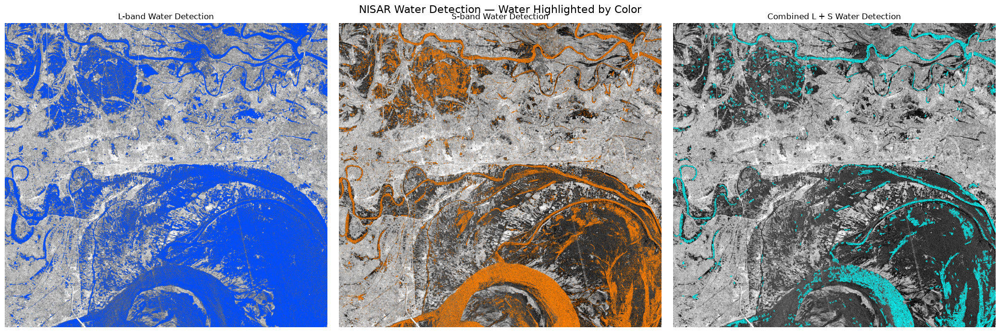


========== WATER AREA ==========
L-only : 1,496,875 pixels (35.10%)
S-only : 592,110 pixels (13.88%)
L+S refined : 225,339 pixels (5.28%)


In [36]:
# ==========================================================
# VISUAL WATER MAPS
# L-ONLY vs S-ONLY vs COMBINED L+S
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. Create independent L-band and S-band water masks
# ----------------------------------------------------------

L_water_mask = valid & (L < L_THRESHOLD)
S_water_mask = valid & (S < S_THRESHOLD)

# Combined mask already created earlier
LS_water_mask = refined_water_mask

print("==============================================")
print("       SINGLE + DUAL FREQUENCY WATER")
print("==============================================")

print("L-only water pixels :", np.sum(L_water_mask))
print("S-only water pixels :", np.sum(S_water_mask))
print("L+S refined pixels  :", np.sum(LS_water_mask))


# ----------------------------------------------------------
# 2. Create RGB-style overlays
# ----------------------------------------------------------

# Use L-band as grayscale background
background = L.copy()

# Normalize background for display
valid_background = background[valid]

vmin = np.percentile(valid_background, 2)
vmax = np.percentile(valid_background, 98)

background_norm = np.clip(
    (background - vmin) / (vmax - vmin),
    0,
    1
)

# Create RGB image
rgb_L = np.dstack([
    background_norm,
    background_norm,
    background_norm
])

# ----------------------------------------------------------
# L-only water = BLUE
# ----------------------------------------------------------

L_overlay = rgb_L.copy()

L_overlay[L_water_mask] = [0.0, 0.3, 1.0]

# ----------------------------------------------------------
# S-only water = ORANGE
# ----------------------------------------------------------

S_overlay = rgb_L.copy()

S_overlay[S_water_mask] = [1.0, 0.5, 0.0]

# ----------------------------------------------------------
# Combined L+S water = CYAN
# ----------------------------------------------------------

LS_overlay = rgb_L.copy()

LS_overlay[LS_water_mask] = [0.0, 1.0, 1.0]


# ----------------------------------------------------------
# 3. Display
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

axes[0].imshow(L_overlay)
axes[0].set_title("L-band Water Detection")
axes[0].axis("off")

axes[1].imshow(S_overlay)
axes[1].set_title("S-band Water Detection")
axes[1].axis("off")

axes[2].imshow(LS_overlay)
axes[2].set_title("Combined L + S Water Detection")
axes[2].axis("off")

plt.suptitle(
    "NISAR Water Detection — Water Highlighted by Color",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 4. Water area percentages
# ----------------------------------------------------------

total_valid = np.sum(valid)

print("\n========== WATER AREA ==========")

print(
    f"L-only : {np.sum(L_water_mask):,} pixels "
    f"({np.sum(L_water_mask)/total_valid*100:.2f}%)"
)

print(
    f"S-only : {np.sum(S_water_mask):,} pixels "
    f"({np.sum(S_water_mask)/total_valid*100:.2f}%)"
)

print(
    f"L+S refined : {np.sum(LS_water_mask):,} pixels "
    f"({np.sum(LS_water_mask)/total_valid*100:.2f}%)"
)

In [37]:
# ==========================================================
# CHECK ALL AVAILABLE NISAR L-BAND / S-BAND GeoTIFFs
# ==========================================================

from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("=" * 60)
print("AVAILABLE NISAR HHHH GeoTIFFs")
print("=" * 60)

print("\nL-BAND FILES:")
print("-" * 40)

L_ALL = sorted(OUTPUT_DIR.rglob("*LSAR*/*HHHH.tif"))

for i, f in enumerate(L_ALL):
    print(f"{i}: {f}")

print("\nS-BAND FILES:")
print("-" * 40)

S_ALL = sorted(OUTPUT_DIR.rglob("*SSAR*/*HHHH.tif"))

for i, f in enumerate(S_ALL):
    print(f"{i}: {f}")

print("\nTotal L-band files:", len(L_ALL))
print("Total S-band files:", len(S_ALL))

AVAILABLE NISAR HHHH GeoTIFFs

L-BAND FILES:
----------------------------------------
0: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif

S-BAND FILES:
----------------------------------------
0: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif

Total L-band files: 1
Total S-band files: 1


CLEAR WATER VISUALIZATION


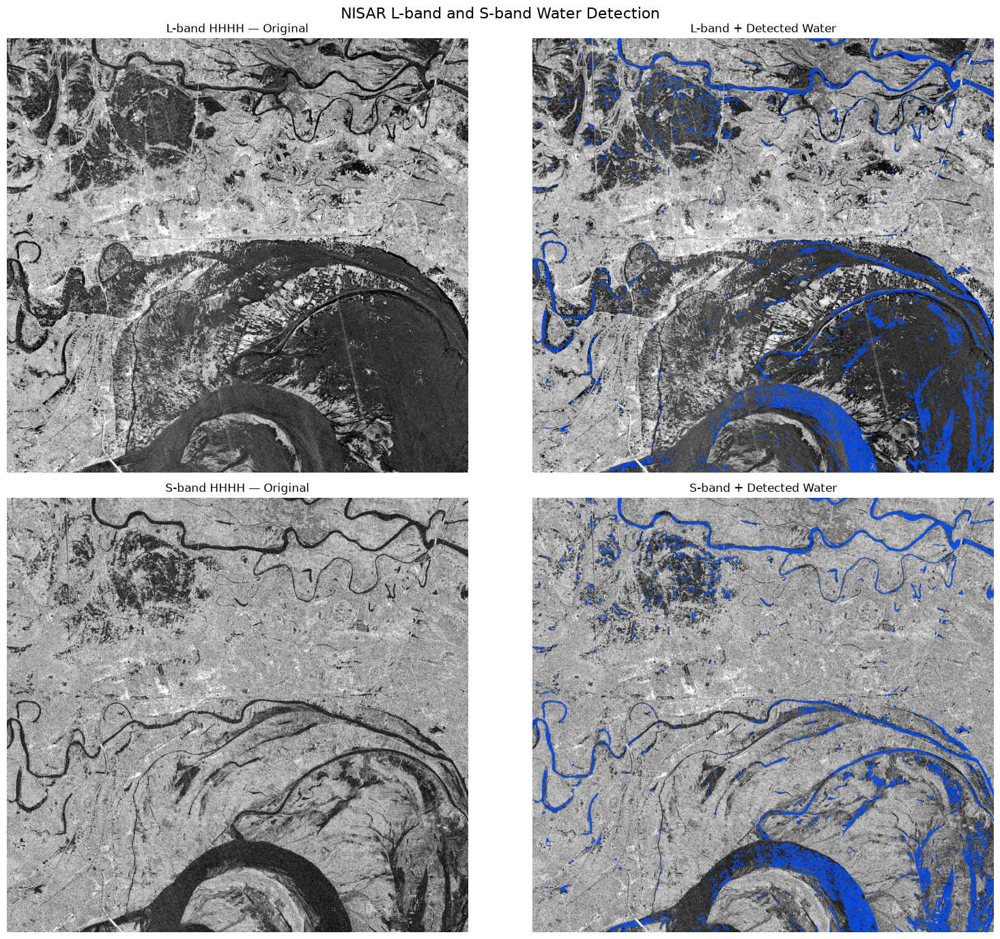

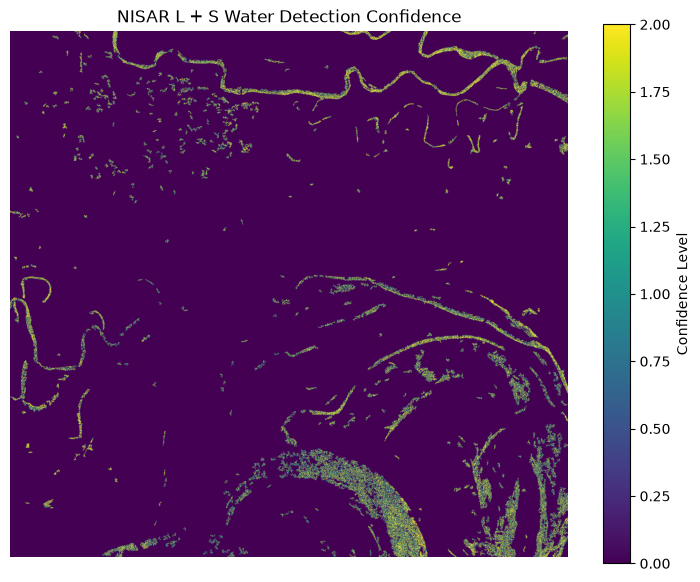


Blue = detected water
Confidence map shows detection confidence.


In [38]:
# ==========================================================
# CLEAR WATER VISUALIZATION
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 55)
print("CLEAR WATER VISUALIZATION")
print("=" * 55)

# ----------------------------------------------------------
# 1. Create RGB-style overlays
# ----------------------------------------------------------

# Use L-band as the background
L_background = L.copy()

# Normalize L-band for display
valid_L = np.isfinite(L_background)

L_min = np.percentile(L_background[valid_L], 2)
L_max = np.percentile(L_background[valid_L], 98)

L_norm = np.clip(
    (L_background - L_min) / (L_max - L_min),
    0,
    1
)

# Make grayscale RGB image
L_rgb = np.dstack([
    L_norm,
    L_norm,
    L_norm
])

# Put detected water in blue
water_overlay_L = L_rgb.copy()

water_overlay_L[refined_water_mask] = [0.0, 0.3, 1.0]


# ----------------------------------------------------------
# 2. Do the same for S-band
# ----------------------------------------------------------

S_background = S.copy()

valid_S = np.isfinite(S_background)

S_min = np.percentile(S_background[valid_S], 2)
S_max = np.percentile(S_background[valid_S], 98)

S_norm = np.clip(
    (S_background - S_min) / (S_max - S_min),
    0,
    1
)

S_rgb = np.dstack([
    S_norm,
    S_norm,
    S_norm
])

water_overlay_S = S_rgb.copy()

water_overlay_S[refined_water_mask] = [0.0, 0.3, 1.0]


# ----------------------------------------------------------
# 3. Display results
# ----------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# L-band original
axes[0, 0].imshow(L_norm, cmap="gray")
axes[0, 0].set_title("L-band HHHH — Original")
axes[0, 0].axis("off")

# L-band + water
axes[0, 1].imshow(water_overlay_L)
axes[0, 1].set_title("L-band + Detected Water")
axes[0, 1].axis("off")

# S-band original
axes[1, 0].imshow(S_norm, cmap="gray")
axes[1, 0].set_title("S-band HHHH — Original")
axes[1, 0].axis("off")

# S-band + water
axes[1, 1].imshow(water_overlay_S)
axes[1, 1].set_title("S-band + Detected Water")
axes[1, 1].axis("off")

plt.suptitle(
    "NISAR L-band and S-band Water Detection",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 4. Confidence map
# ----------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.imshow(confidence_map, cmap="viridis")
plt.colorbar(label="Confidence Level")

plt.title("NISAR L + S Water Detection Confidence")
plt.axis("off")

plt.show()

print("\nBlue = detected water")
print("Confidence map shows detection confidence.")

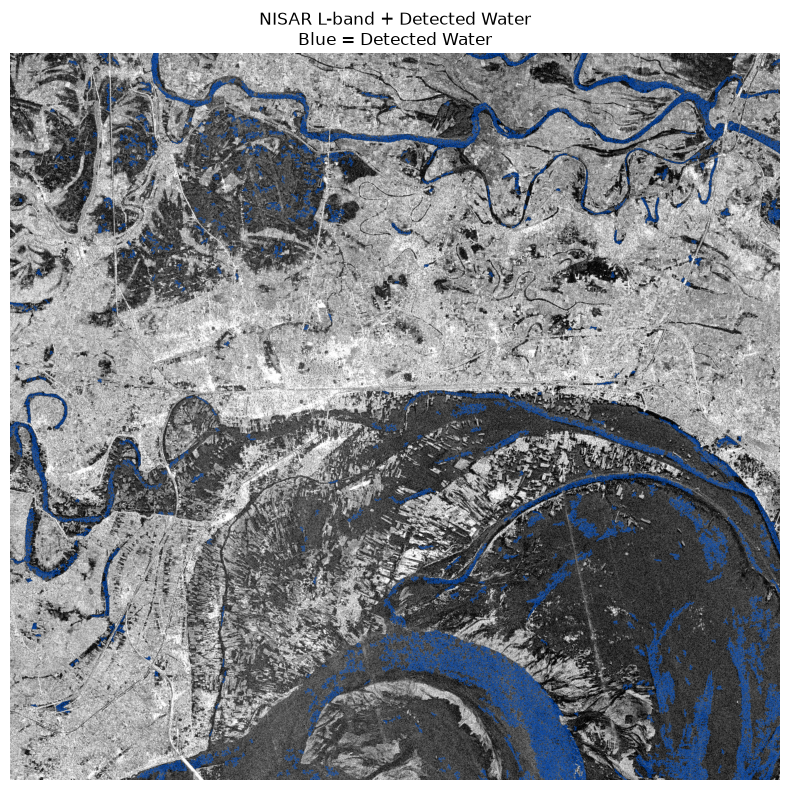

In [39]:
# ==========================================================
# CLEAR WATER DETECTION OVERLAY
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

# Create RGB-style grayscale background
L_norm = np.clip(
    (L - np.nanpercentile(L, 2)) /
    (np.nanpercentile(L, 98) - np.nanpercentile(L, 2)),
    0, 1
)

# Make RGB image from L-band
rgb = np.dstack([L_norm, L_norm, L_norm])

# Create colored water overlay
overlay = np.zeros_like(rgb)

# Water = blue
overlay[refined_water_mask] = [0, 0.4, 1.0]

# Blend original + water
alpha = 0.55

result = rgb.copy()

result[refined_water_mask] = (
    (1 - alpha) * rgb[refined_water_mask]
    + alpha * overlay[refined_water_mask]
)

plt.figure(figsize=(12, 8))

plt.imshow(result)

plt.title(
    "NISAR L-band + Detected Water\n"
    "Blue = Detected Water"
)

plt.axis("off")
plt.tight_layout()
plt.show()

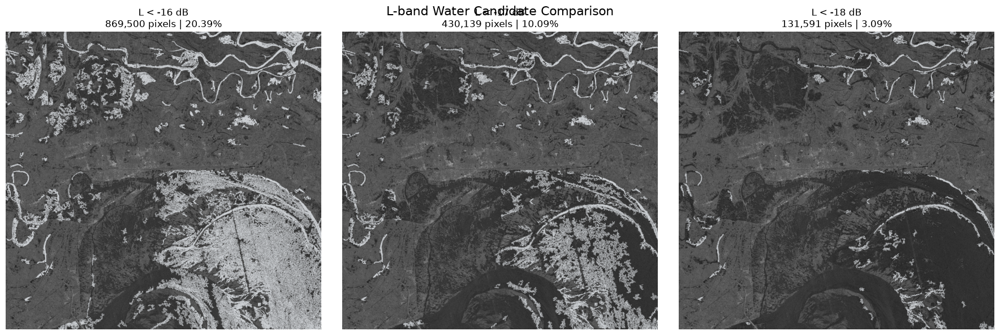

In [45]:
# ==========================================================
# L-BAND WATER DETECTION - THRESHOLD COMPARISON
# ==========================================================

from scipy import ndimage
import matplotlib.pyplot as plt
import numpy as np

thresholds = [-16, -17, -18]

MIN_REGION_SIZE = 300

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

for ax, threshold in zip(axes, thresholds):

    # ----------------------------------------------
    # Initial threshold
    # ----------------------------------------------

    mask = (
        L_valid &
        (L < threshold)
    )

    # ----------------------------------------------
    # Connected components
    # ----------------------------------------------

    labeled, num_regions = ndimage.label(mask)

    region_sizes = np.bincount(
        labeled.ravel()
    )

    keep = region_sizes >= MIN_REGION_SIZE

    # IMPORTANT:
    # remove background label
    keep[0] = False

    clean = keep[labeled]

    clean &= L_valid

    # ----------------------------------------------
    # Display
    # ----------------------------------------------

    L_display = np.where(
        L_valid,
        L,
        np.nan
    )

    ax.imshow(
        L_display,
        cmap="gray"
    )

    overlay = np.ma.masked_where(
        ~clean,
        clean
    )

    ax.imshow(
        overlay,
        cmap="Blues",
        alpha=0.8
    )

    pixels = np.sum(clean)

    percentage = (
        pixels /
        np.sum(L_valid) *
        100
    )

    ax.set_title(
        f"L < {threshold} dB\n"
        f"{pixels:,} pixels | {percentage:.2f}%"
    )

    ax.axis("off")

plt.suptitle(
    "L-band Water Candidate Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

12 SEP
  mean: -11.954447
  median: -12.060825

30 OCT
  mean: -10.341047
  median: -9.806745


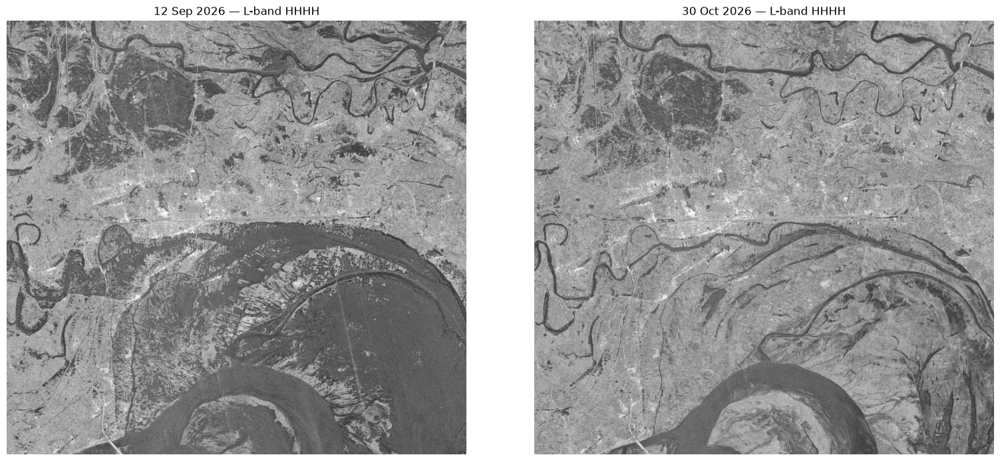

In [65]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training"
)

SEP12 = (
    PROJECT_DIR
    / "outputs"
    / "module_08_visualization"
    / "NISAR_LSAR_098_014_A_20260912"
    / "HHHH.tif"
)

OCT30 = (
    PROJECT_DIR
    / "outputs"
    / "module_08_visualization"
    / "NISAR_LSAR_098_014_A_20261030"
    / "HHHH.tif"
)

def load_sar_db(path):
    with rasterio.open(path) as src:
        x = src.read(1).astype(np.float32)

    valid = np.isfinite(x) & (x > 0)

    db = np.full_like(x, np.nan)
    db[valid] = 10 * np.log10(x[valid])

    return db

sep12_db = load_sar_db(SEP12)
oct30_db = load_sar_db(OCT30)

print("12 SEP")
print("  mean:", np.nanmean(sep12_db))
print("  median:", np.nanmedian(sep12_db))

print("\n30 OCT")
print("  mean:", np.nanmean(oct30_db))
print("  median:", np.nanmedian(oct30_db))

# EXACT SAME DISPLAY SCALE FOR BOTH
vmin = -30
vmax = 5

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(sep12_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("12 Sep 2026 — L-band HHHH")
axes[0].axis("off")

axes[1].imshow(oct30_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("30 Oct 2026 — L-band HHHH")
axes[1].axis("off")

plt.tight_layout()
plt.show()

12 SEP 2026
Water pixels: 902845
Water %: 21.169909837749216

30 OCT 2026
Water pixels: 431898
Water %: 10.127144436868136


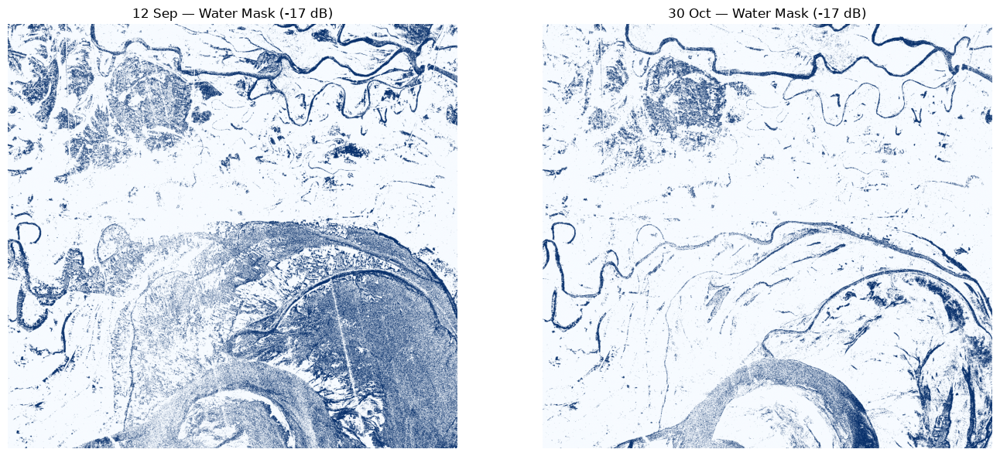

In [67]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

THRESHOLD_DB = -17.0

def make_water_mask(path):
    with rasterio.open(path) as src:
        x = src.read(1).astype(np.float32)
        profile = src.profile.copy()

    valid = np.isfinite(x) & (x > 0)

    db = np.full_like(x, np.nan)
    db[valid] = 10 * np.log10(x[valid])

    mask = valid & (db < THRESHOLD_DB)

    return db, mask, profile


sep12_db, sep12_mask, sep12_profile = make_water_mask(SEP12)
oct30_db, oct30_mask, oct30_profile = make_water_mask(OCT30)

print("=" * 60)
print("12 SEP 2026")
print("=" * 60)
print("Water pixels:", np.sum(sep12_mask))
print("Water %:", 100 * np.sum(sep12_mask) / np.sum(np.isfinite(sep12_db)))

print("\n" + "=" * 60)
print("30 OCT 2026")
print("=" * 60)
print("Water pixels:", np.sum(oct30_mask))
print("Water %:", 100 * np.sum(oct30_mask) / np.sum(np.isfinite(oct30_db)))

# Show the masks side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(sep12_mask, cmap="Blues")
ax[0].set_title("12 Sep — Water Mask (-17 dB)")
ax[0].axis("off")

ax[1].imshow(oct30_mask, cmap="Blues")
ax[1].set_title("30 Oct — Water Mask (-17 dB)")
ax[1].axis("off")

plt.tight_layout()
plt.show()